## Extração de características

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Mesma divisão do notebook 03 do AVI, agora com vários canais.

**Grupo A — SSVEP** (canais occipitais, uma característica por frequência candidata, 40 de cada)

| característica | ideia |
|---|---|
| `snr_e` | SNR de **banda estreita** (eq. 3 do artigo do BETA) |
| `snr_l` | SNR de **banda larga** (eq. 4), que soma 5 harmônicos e usa todo o espectro como ruído |
| `cca` | correlação canônica entre os 9 canais e as referências seno/cosseno (5 harmônicos) |

**Grupo B — Ritmos** (canais frontais/centrais): potência relativa teta, alfa, beta, beta1, beta2, beta3 e razão teta/beta.

Os alvos vão de 8 a 15,8 Hz e o 2º harmônico de 16 a 31,6 Hz, então o estímulo cai **dentro de alfa e de beta**. Na extração não dá para tirar isso, porque seria preciso saber o alvo (vazamento).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from glob import glob

fs = 250
nfft = 5 * fs
fr = np.fft.rfftfreq(nfft, 1 / fs)

arquivos = sorted(glob('dados/epocas/S*.npz'), key=lambda a: int(a.split('S')[-1][:-4]))
SUJEITOS = [int(a.split('S')[-1][:-4]) for a in arquivos]
FREQS = np.load(f'dados/npz/S{SUJEITOS[0]}.npz')['freqs']
print(len(SUJEITOS), 'participantes,', len(FREQS), 'alvos')

70 participantes, 40 alvos


### SNR de banda estreita e de banda larga

Definições do artigo (Liu et al., 2020):

$SNR_{estreita} = 20 \log_{10} \frac{y(f)}{\sum_{k=1}^{5}[y(f-k\Delta f) + y(f+k\Delta f)]/10}$

$SNR_{larga} = 10 \log_{10} \frac{\sum_{k=1}^{N_h} P(k f)}{\sum_{f=0}^{f_s/2} P(f) - \sum_{k=1}^{N_h} P(k f)}$

com $y$ o espectro de amplitude, $P$ o de potência e $N_h = 5$. Como no artigo, completo a janela com zeros até 5 s para ter resolução de **0,2 Hz**, o passo entre os alvos, e faço a média dos 9 canais.

In [2]:
def espectro(x):
    A = np.abs(np.fft.rfft(x, n=nfft, axis=-1))
    return A, A ** 2


def indice(f):
    return np.argmin(np.abs(fr - f))


def snr_estreita(A, f):
    i = indice(f)
    viz = np.concatenate((A[..., i - 5:i], A[..., i + 1:i + 6]), axis=-1).mean(axis=-1)
    return (20 * np.log10(A[..., i] / viz)).mean(axis=-1)


def snr_larga(P, f, nh=5):
    sinal = P[..., [indice(h * f) for h in range(1, nh + 1)]].sum(axis=-1)
    return (10 * np.log10(sinal / (P.sum(axis=-1) - sinal))).mean(axis=-1)

### CCA

Para cada frequência candidata $f$, a referência tem senos e cossenos de $f$ até $5f$. A correlação canônica é o maior valor singular de $Q_X^T Q_Y$, com $Q_X$ e $Q_Y$ vindos da decomposição QR dos sinais centralizados (o mesmo que o `CCA` do `sklearn`, só que mais rápido).

In [3]:
def referencias(f, n=2 * fs, nh=5):
    t = np.arange(n) / fs
    return np.column_stack([fun(2 * np.pi * h * f * t) for h in range(1, nh + 1) for fun in (np.sin, np.cos)])


REFS = [np.linalg.qr(R - R.mean(axis=0))[0] for R in (referencias(f) for f in FREQS)]


def cca(x):
    qx = np.linalg.qr((x - x.mean(axis=-1, keepdims=True)).T)[0]
    return np.array([np.linalg.svd(qx.T @ qy, compute_uv=False)[0] for qy in REFS])

### Ritmos

Mesmas faixas do `EEG_Rhythms`. A potência relativa é a fração da potência de 4 a 40 Hz, com a média dos 9 canais frontais/centrais.

In [4]:
BANDAS = {'teta': (4, 8), 'alfa': (8, 13), 'beta': (13, 30),
          'beta1': (13, 15), 'beta2': (15, 20), 'beta3': (20, 30)}


def ritmos(x):
    f, P = signal.periodogram(x, fs=fs, window='hann', axis=-1)
    P = P.mean(axis=-2)
    pot = {k: P[..., (f >= a) & (f < b)].sum(axis=-1) for k, (a, b) in BANDAS.items()}
    total = P[..., (f >= 4) & (f < 40)].sum(axis=-1)
    return np.stack([pot[k] / total for k in BANDAS] + [pot['teta'] / pot['beta']], axis=-1)


NOMES_RITMOS = [f'rel_{k}' for k in BANDAS] + ['razao_teta_beta']

### Extração para todos os participantes

In [5]:
F, meta = [], []
for s in SUJEITOS:
    ep = np.load(f'dados/epocas/S{s}.npz')
    A, P = espectro(ep['ssvep'])
    rit = ritmos(ep['ritmo'])
    for b in range(4):
        for c in range(40):
            snr_e = [snr_estreita(A[b, c], f) for f in FREQS]
            snr_l = [snr_larga(P[b, c], f) for f in FREQS]
            F.append(np.concatenate((snr_e, snr_l, cca(ep['ssvep'][b, c]), rit[b, c])))
            meta.append((s, b, c, FREQS[c]))

F, meta = np.array(F), np.array(meta)
NOMES = [f'{t}_{f:.1f}' for t in ('snr_e', 'snr_l', 'cca') for f in FREQS] + NOMES_RITMOS
np.save('dados/caracteristicas.npy', F)
np.save('dados/meta.npy', meta)
np.save('dados/nomes_caracteristicas.npy', np.array(NOMES))
print(F.shape, '-> (ensaios, características)')

(11200, 127) -> (ensaios, características)


### Verificando as características

Uma boa característica SSVEP tem valor máximo quando a frequência candidata é a estimulada, formando uma diagonal. Normalizo cada linha para a diagonal aparecer em todas as frequências.

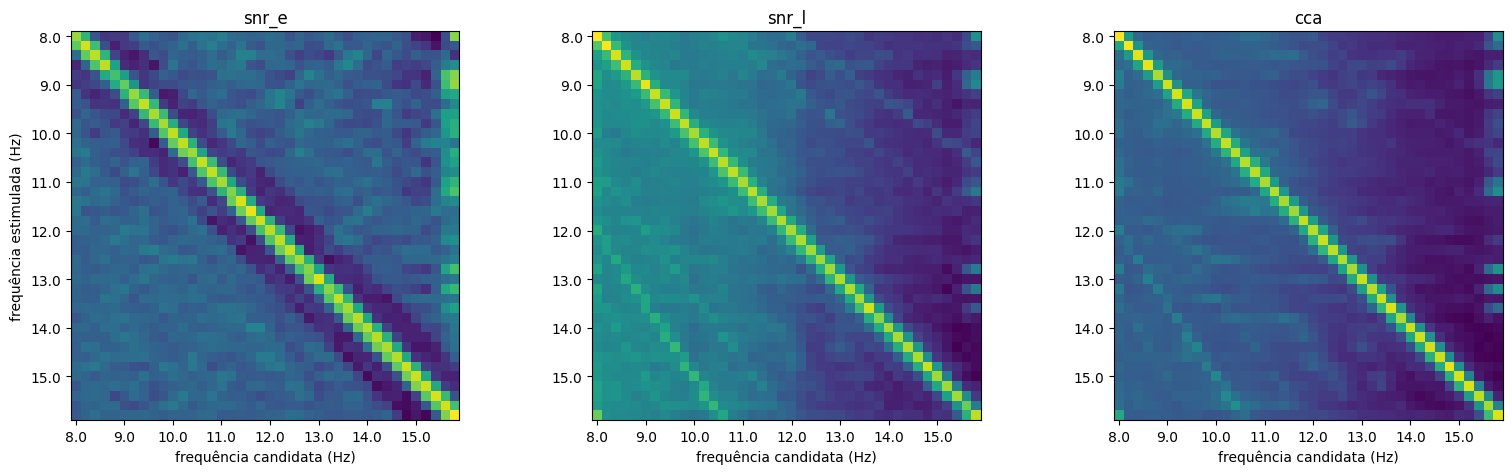

In [6]:
y = meta[:, 2].astype(int)
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))
for k, (eixo, tipo) in enumerate(zip(eixos, ('snr_e', 'snr_l', 'cca'))):
    M = np.array([F[y == c, 40 * k:40 * (k + 1)].mean(axis=0) for c in range(40)])
    M = (M - M.mean(axis=1, keepdims=True)) / M.std(axis=1, keepdims=True)
    eixo.imshow(M, cmap='viridis')
    eixo.set_xticks(range(0, 40, 5), FREQS[::5]); eixo.set_yticks(range(0, 40, 5), FREQS[::5])
    eixo.set_xlabel('frequência candidata (Hz)'); eixo.set_title(tipo)
eixos[0].set_ylabel('frequência estimulada (Hz)')
plt.tight_layout(); plt.show()

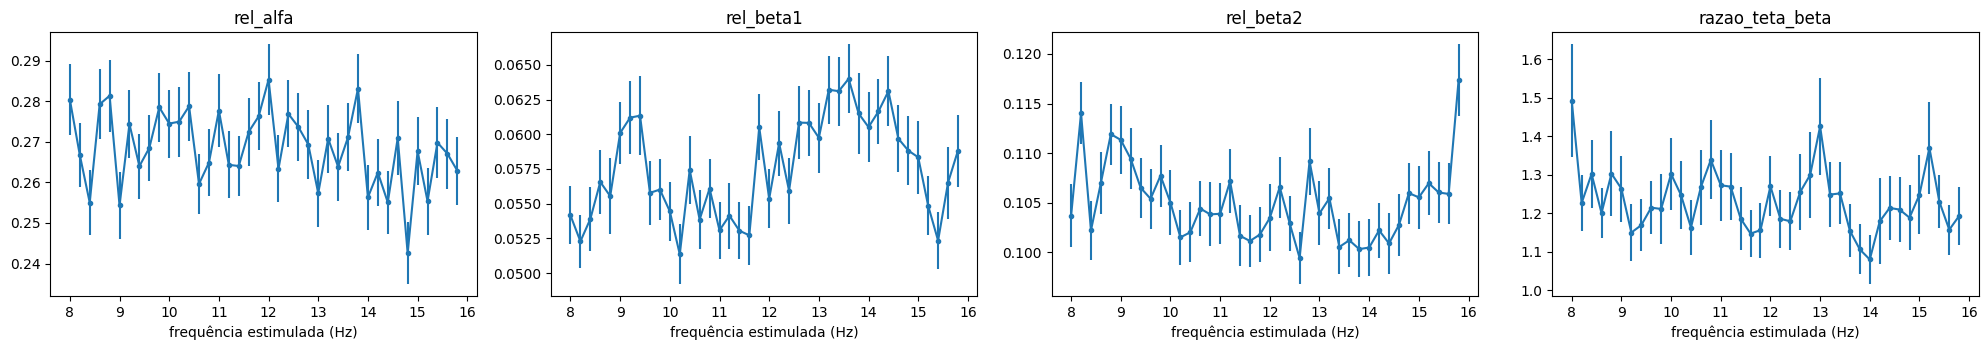

In [7]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 3.6))
for eixo, nome in zip(eixos, ('rel_alfa', 'rel_beta1', 'rel_beta2', 'razao_teta_beta')):
    j = NOMES.index(nome)
    m = np.array([F[y == c, j].mean() for c in range(40)])
    e = np.array([F[y == c, j].std() / np.sqrt((y == c).sum()) for c in range(40)])
    eixo.errorbar(FREQS, m, e, fmt='o-', ms=3)
    eixo.set_title(nome); eixo.set_xlabel('frequência estimulada (Hz)')
plt.tight_layout(); plt.show()

- A diagonal aparece nas três características SSVEP, mais limpa no CCA e mais borrada no SNR de banda estreita.
- Os ritmos frontais mudam um pouco com o alvo: a beta1 (13–15 Hz) sobe quando o alvo está entre 13 e 14,4 Hz, e a beta2 (15–20 Hz) dá um salto em 15,8 Hz. É a contaminação pelo próprio estímulo descrita acima, e por isso o notebook 05 usa o trecho antes do estímulo.